In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/inhuman44/cifar10/cifar-10-batches-py/batches.meta
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-batches-py/data_batch_1
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-batches-py/data_batch_2
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-batches-py/data_batch_3
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-batches-py/data_batch_4
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-batches-py/data_batch_5
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-batches-py/readme.html
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-batches-py/test_batch
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-python/cifar-10-batches-py/batches.meta
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-python/cifar-10-batches-py/data_batch_1
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-python/cifar-10-batches-py/data_batch_2
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-python/cifar-10-batches-py/data_batch_3
/kaggle/input/datasets/inhuman44/cifar10/cifar-10-p

In [2]:
%cd /kaggle/working

!git clone https://github.com/JayRothenberger/Meta-Co-Training.git

%cd /kaggle/working/Meta-Co-Training

print("Repository cloned successfully.")

/kaggle/working
Cloning into 'Meta-Co-Training'...
remote: Enumerating objects: 218, done.
remote: Counting objects: 100% (162/162), done.
remote: Compressing objects: 100% (109/109), done.
remote: Total 218 (delta 96), reused 112 (delta 53), pack-reused 56 (from 1)
Receiving objects: 100% (218/218), 60.64 MiB | 43.40 MiB/s, done.
Resolving deltas: 100% (111/111), done.
/kaggle/working/Meta-Co-Training
Repository cloned successfully.


In [4]:
import os
import sys
import gc
import time
import random
import numpy as np
import pandas as pd

import torch
import torchvision
import torch.nn as nn
import torch.optim as optim

from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Subset

In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device configurations
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Cache directories
os.environ["HF_HOME"] = "/kaggle/working/hf_cache"
os.environ["TORCH_HOME"] = "/kaggle/working/torch_cache"

os.makedirs(os.environ["HF_HOME"], exist_ok=True)
os.makedirs(os.environ["TORCH_HOME"], exist_ok=True)

# Verify environment
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


In [6]:
print("CUDA available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

CUDA available: True
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [7]:
%cd /kaggle/working/Meta-Co-Training/meta-cotraining
!pip install -e . --no-deps

/kaggle/working/Meta-Co-Training/meta-cotraining
Obtaining file:///kaggle/working/Meta-Co-Training/meta-cotraining
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for mct (pyproject.toml) ... done
  Created wheel for mct: filename=mct-0.0.1-0.editable-py3-none-any.whl size=2527 sha256=1e8eb35b3e355f1efee469b035509af692ae47b50dd82024d325b65e9048a2a4
  Stored in directory: /tmp/pip-ephem-wheel-cache-0s5kkt0q/wheels/b6/69/89/d206f460a5e51dd7e607e9f9962626771565b71e2fb66eed03
Successfully built mct


In [8]:
src_path = os.path.join(os.getcwd(), "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

import mct

print("MCT package imported successfully.")

MCT package imported successfully.


In [9]:
import timm
import transformers
import sklearn
import scipy
import skimage

print("timm:", timm.__version__)
print("transformers:", transformers.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy:", scipy.__version__)
print("scikit-image:", skimage.__version__)

timm: 1.0.29
transformers: 5.16.1
scikit-learn: 1.6.1
scipy: 1.16.3
scikit-image: 0.25.2


In [10]:
!pip install git+https://github.com/openai/CLIP.git --no-deps

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-d06a642u
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-d06a642u
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369548 sha256=05cd95eca7bd314e9fa8be7337bb76dba2d483eb69d514a7de4b24f9169f4a35
  Stored in directory: /tmp/pip-ephem-wheel-cache-9v9ff58a/wheels/cb/a8/74/5f32d6cf0407457f0f62737b6da5c14eb86b9cac476fdf630d
Successfully built clip


In [11]:
!pip install ftfy

In [12]:
from mct.image_models import (
    DINOv2_distance,
    CLIP_distance,
    IMAGE_TRANSFORMS,
    IMAGE_DISTANCES
)

print("Available encoders:", list(IMAGE_DISTANCES.keys()))
print("Available transforms:", list(IMAGE_TRANSFORMS.keys()))

/kaggle/working/Meta-Co-Training/meta-cotraining/src/mct/image_models.py:986: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  or pretrained_layers[0] is '*'
/kaggle/working/Meta-Co-Training/meta-cotraining/src/mct/image_models.py:1045: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  or (len(frozen_layers) > 0 and frozen_layers[0] is '*')
/kaggle/working/Meta-Co-Training/meta-cotraining/src/mct/image_models.py:1056: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  or (len(frozen_layers) > 0 and frozen_layers[0] is '*')
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Available encoders: ['EMD', 'Hist', 'CLIP', 'BLIPv2', 'OWLv2', 'ALIGN', 'Heira', 'SigLIP', 'EsViT', 'MAE', 'DINOv2', 'SwAV']
Available transforms: ['CLIP', 'OWLv2', 'SigLIP', 'EsViT', 'MAE', 'DINOv2', 'ALIGN', 'Heira', 'BLIPv2', 'SwAV']


In [13]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [14]:
for root, dirs, files in os.walk("/kaggle/input/datasets"):
    print("Directory:", root)
    print("Files:", files[:10])

Directory: /kaggle/input/datasets
Files: []
Directory: /kaggle/input/datasets/inhuman44
Files: []
Directory: /kaggle/input/datasets/inhuman44/cifar10
Files: []
Directory: /kaggle/input/datasets/inhuman44/cifar10/cifar-10-batches-py
Files: ['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']
Directory: /kaggle/input/datasets/inhuman44/cifar10/cifar-10-python
Files: []
Directory: /kaggle/input/datasets/inhuman44/cifar10/cifar-10-python/cifar-10-batches-py
Files: ['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


In [18]:
# from torchvision.datasets import CIFAR10

# train_dataset = CIFAR10(
#     root="/kaggle/working/data",
#     train=True,
#     download = True,
#     transform = None
# )

# test_dataset = CIFAR10(
#     root="/kaggle/working/data",
#     train = False,
#     download = True,
#     transform = None
# )

# print("Training samples:", len(train_dataset))
# print("Testing samples:", len(test_dataset))
# print("Number of classes:", len(train_dataset.classes))
# print("Classes:", train_dataset.classes)

100%|██████████| 170M/170M [14:28<00:00, 196kB/s] 


Training samples: 50000
Testing samples: 10000
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [19]:
# import shutil

# shutil.make_archive(
#     "/kaggle/working/cifar10_backup",
#     "zip",
#     "/kaggle/working/data"
# )

'/kaggle/working/cifar10_backup.zip'

In [15]:
from torchvision.datasets import CIFAR10

DATA_DIR = "/kaggle/input/datasets/inhuman44/cifar10"

train_dataset = CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=None
)

test_dataset = CIFAR10(
    root=DATA_DIR,
    train=False,
    download=False,
    transform=None
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)

Training samples: 50000
Testing samples: 10000
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


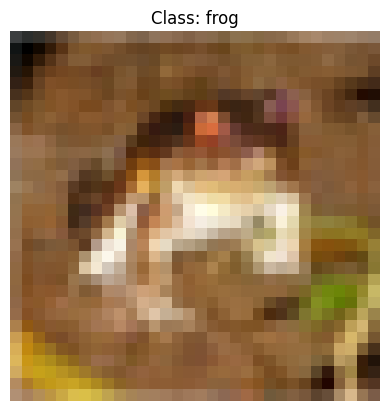

In [16]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]

plt.imshow(image)
plt.title(f"Class: {train_dataset.classes[label]}")
plt.axis("off")
plt.show()

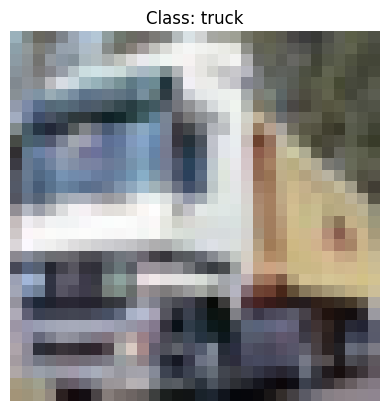

In [17]:
import matplotlib.pyplot as plt

image, label = train_dataset[1]

plt.imshow(image)
plt.title(f"Class: {train_dataset.classes[label]}")
plt.axis("off")
plt.show()

In [18]:
from mct.image_models import IMAGE_TRANSFORMS

print("DINOv2 transformations:")
print(IMAGE_TRANSFORMS["DINOv2"])

print("\nCLIP transformations:")
print(IMAGE_TRANSFORMS["CLIP"])

DINOv2 transformations:
Compose(
      ToTensor()
      Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
      CenterCrop(size=(224, 224))
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

CLIP transformations:
Compose(
      ToTensor()
      Resize(size=(256, 256), interpolation=bilinear, max_size=None, antialias=True)
      CenterCrop(size=(224, 224))
      Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)


In [19]:
from torch.utils.data import Dataset

class CIFAR10TwoViews(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
        self.dino_transform = IMAGE_TRANSFORMS["DINOv2"]
        self.clip_transform = IMAGE_TRANSFORMS["CLIP"]

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]

        dino_view = self.dino_transform(image)
        clip_view = self.clip_transform(image)
    
        return dino_view, clip_view, label

train_two_views = CIFAR10TwoViews(train_dataset)
test_two_views = CIFAR10TwoViews(test_dataset)

print("Training samples:", len(train_two_views))
print("Testing samples:", len(test_two_views))

Training samples: 50000
Testing samples: 10000


In [20]:
dino_image, clip_image, label = train_two_views[0]

print("DINOv2 image shape:", dino_image.shape)
print("CLIP image shape:", clip_image.shape)
print("Label:", label)
print("Class:", train_dataset.classes[label])

DINOv2 image shape: torch.Size([3, 224, 224])
CLIP image shape: torch.Size([3, 224, 224])
Label: 6
Class: frog


In [21]:
import inspect

print("DINOv2 initialization:")
print(inspect.signature(DINOv2_distance))

print("\nCLIP initialization:")
print(inspect.signature(CLIP_distance))

DINOv2 initialization:
(model='dinov2_vitl14_reg')

CLIP initialization:
(model='ViT-B/16')


In [23]:
dino_encoder = DINOv2_distance()

dino_model = dino_encoder.model
dino_model = dino_model.to("cuda:0")
dino_model.eval()

print("DINOv2 loaded successfully")
print("Device:", next(dino_model.parameters()).device)


/usr/local/lib/python3.13/dist-packages/torch/hub.py:275: UserWarning: TORCH_HUB is deprecated, please use env TORCH_HOME instead
  hub_dir = get_dir()
/usr/local/lib/python3.13/dist-packages/torch/hub.py:356: UserWarning: TORCH_HUB is deprecated, please use env TORCH_HOME instead
  hub_dir = get_dir()


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to ./hub/main.zip


/kaggle/working/Meta-Co-Training/meta-cotraining/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/kaggle/working/Meta-Co-Training/meta-cotraining/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/kaggle/working/Meta-Co-Training/meta-cotraining/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
/usr/local/lib/python3.13/dist-packages/torch/hub.py:878: UserWarning: TORCH_HUB is deprecated, please use env TORCH_HOME instead
  hub_dir = get_dir()


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitl14/dinov2_vitl14_reg4_pretrain.pth" to ./hub/checkpoints/dinov2_vitl14_reg4_pretrain.pth


100%|██████████| 1.13G/1.13G [00:03<00:00, 372MB/s]


DINOv2 loaded successfully
Device: cuda:0


In [25]:
clip_encoder = CLIP_distance()

clip_model = clip_encoder.model
clip_model = clip_model.to("cuda:1")
clip_model.eval()

print("CLIP loaded successfully.")
print("Device:", next(clip_model.parameters()).device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
logit_scale                               

CLIP loaded successfully.
Device: cuda:1


In [26]:
dino_image, clip_image, label = train_two_views[0]

with torch.no_grad():
    dino_features = dino_model(dino_image.unsqueeze(0).to("cuda:0"))
    clip_features = clip_model(clip_image.unsqueeze(0).to("cuda:1"))

print("DINOv2 feature shape:", dino_features.shape)
print("CLIP feature shape:", clip_features.shape)

DINOv2 feature shape: torch.Size([1, 1024])
CLIP feature shape: torch.Size([1, 768])


In [27]:
import shutil

for i in range(torch.cuda.device_count()):
    free, total = torch.cuda.mem_get_info(i)

    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
    print(f"Total memory: {total / 1024**3:.2f} GB")
    print(f"Free memory: {free / 1024**3:.2f} GB")
    print()

disk = shutil.disk_usage("/kaggle/working")

print(f"Available disk space: {disk.free / 1024**3:.2f} GB")

GPU 0: Tesla T4
Total memory: 14.56 GB
Free memory: 13.26 GB

GPU 1: Tesla T4
Total memory: 14.56 GB
Free memory: 14.05 GB

Available disk space: 17.12 GB


In [28]:
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_two_views,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_two_views,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 782
Testing batches: 157


In [30]:
def extract_features(loader):
    dino_features_list = []
    clip_features_list = []
    labels_list = []

    dino_model.eval()
    clip_model.eval()

    with torch.no_grad():
        for dino_images, clip_images, labels in loader:

            dino_images = dino_images.to("cuda:0")
            clip_images = clip_images.to("cuda:1")

            dino_features = dino_model(dino_images)
            clip_features = clip_model(clip_images)

            dino_features_list.append(dino_features.cpu())
            clip_features_list.append(clip_features.cpu())
            labels_list.append(labels)

    dino_features = torch.cat(dino_features_list)
    clip_features = torch.cat(clip_features_list)
    labels = torch.cat(labels_list)

    return dino_features, clip_features, labels

In [31]:
from itertools import islice

test_subset_loader = list(islice(train_loader, 2))

dino_test_features, clip_test_features, test_labels = extract_features(
    test_subset_loader
)

print("DINOv2 features:", dino_test_features.shape)
print("CLIP features:", clip_test_features.shape)
print("Labels:", test_labels.shape)

DINOv2 features: torch.Size([128, 1024])
CLIP features: torch.Size([128, 768])
Labels: torch.Size([128])


In [32]:
import time

start_time = time.time()

X_train_dino, X_train_clip, y_train = extract_features(train_loader)

X_test_dino, X_test_clip, y_test = extract_features(test_loader)

elapsed_time = time.time() - start_time

print("Feature extraction completed.")
print("Training DINOv2:", X_train_dino.shape)
print("Training CLIP:", X_train_clip.shape)
print("Training labels:", y_train.shape)
print("Testing DINOv2:", X_test_dino.shape)
print("Testing CLIP:", X_test_clip.shape)
print("Testing labels:", y_test.shape)
print(f"Total extraction time: {elapsed_time / 60:.2f} minutes")

Feature extraction completed.
Training DINOv2: torch.Size([50000, 1024])
Training CLIP: torch.Size([50000, 768])
Training labels: torch.Size([50000])
Testing DINOv2: torch.Size([10000, 1024])
Testing CLIP: torch.Size([10000, 768])
Testing labels: torch.Size([10000])
Total extraction time: 53.28 minutes


In [33]:
FEATURE_DIR = "/kaggle/working/cifar10_features"
os.makedirs(FEATURE_DIR, exist_ok=True)

torch.save({
    "X_train_dino": X_train_dino,
    "X_train_clip": X_train_clip,
    "y_train": y_train,
    "X_test_dino": X_test_dino,
    "X_test_clip": X_test_clip,
    "y_test": y_test
}, os.path.join(FEATURE_DIR, "features.pt"))

print("Features saved successfully.")

Features saved successfully.


In [34]:
FEATURE_PATH = "/kaggle/working/cifar10_features/features.pt"

print("File exists:", os.path.exists(FEATURE_PATH))
print("File size:", round(os.path.getsize(FEATURE_PATH) / (1024**3), 2), "GB")

File exists: True
File size: 0.4 GB


In [36]:
import shutil

shutil.make_archive(
    "/kaggle/working/cifar10_features",
    "zip",
    "/kaggle/working/cifar10_features"
)

'/kaggle/working/cifar10_features.zip'

In [38]:
from mct.models import FCNN

print(inspect.getsource(FCNN))

class FCNN(nn.Module):

    def __init__(self, input_dim, output_dim, hidden_dims, normalize=nn.BatchNorm1d, skips=True, activation=nn.LeakyReLU(), dropout=0.0):
        """
        define the structure of the multilayer perceptron

        :int input_dim: number of input dimensions to the model

        :int output_dim: number of output dimensions of the model

        :callable normalize: normalization to apply after each activation

        :list hidden_dims: a list of hidden dimensions

        :bool skips: if True include skip connections, default True

        :callable activation: an activation function
        """
        super(FCNN, self).__init__()
        self.layers = nn.ModuleList()
        
        self.activation = activation
        self.normalize = normalize
        self.skips = skips
        skip = []
        
        if hidden_dims:
            if normalize is not None:
                self.layers.extend([nn.Linear(input_dim, hidden_dims[0]), torch.nn.Dropout(p=dropo

In [39]:
class BaselineClassifier(nn.Module):

    def __init__(self, input_dim, num_classes = 10):
        super().__init__()

        self.classifier = FCNN(
            input_dim = input_dim,
            output_dim = num_classes,
            hidden_dims = [1024, 1024, 1024]
        )

    def forward(self, x):
        return self.classifier(x)

dino_baseline = BaselineClassifier(input_dim = 1024).to("cuda:0")

clip_baseline = BaselineClassifier(input_dim = 728).to("cuda:0")

print("DINOv2 parameters:", sum(p.numel() for p in dino_baseline.parameters()))
print("CLIP parameters:", sum(p.numel() for p in clip_baseline.parameters()))

DINOv2 parameters: 3182602
CLIP parameters: 2879498


In [40]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 256

# DINOv2 datasets
dino_train_dataset = TensorDataset(X_train_dino, y_train)
dino_test_dataset = TensorDataset(X_test_dino, y_test)

# CLIP datasets
clip_train_dataset = TensorDataset(X_train_clip, y_train)
clip_test_dataset = TensorDataset(X_test_clip, y_test)

# DataLoaders
dino_train_loader = DataLoader(
    dino_train_dataset, batch_size=BATCH_SIZE, shuffle=True
)

dino_test_loader = DataLoader(
    dino_test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

clip_train_loader = DataLoader(
    clip_train_dataset, batch_size=BATCH_SIZE, shuffle=True
)

clip_test_loader = DataLoader(
    clip_test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("DINOv2 training batches:", len(dino_train_loader))
print("CLIP training batches:", len(clip_train_loader))

DINOv2 training batches: 196
CLIP training batches: 196


In [41]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Generate one reproducible, stratified split
indices = list(range(len(y_train)))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.10,
    random_state=42,
    stratify=y_train.numpy()
)

# DINOv2
dino_train_loader = DataLoader(
    Subset(dino_train_dataset, train_idx),
    batch_size=256,
    shuffle=True
)

dino_val_loader = DataLoader(
    Subset(dino_train_dataset, val_idx),
    batch_size=256,
    shuffle=False
)

# CLIP
clip_train_loader = DataLoader(
    Subset(clip_train_dataset, train_idx),
    batch_size=256,
    shuffle=True
)

clip_val_loader = DataLoader(
    Subset(clip_train_dataset, val_idx),
    batch_size=256,
    shuffle=False
)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(y_test))

Training samples: 45000
Validation samples: 5000
Test samples: 10000


In [42]:
import copy
import torch.nn.functional as F

def train_classifier(model, train_loader, val_loader, device, epochs=20):

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=0.01
    )

    best_val_loss = float("inf")
    best_model_state = None
    history = []

    start_time = time.time()

    for epoch in range(epochs):

        # Training
        model.train()
        train_loss = 0.0

        for features, labels in train_loader:

            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(features)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)

        # Validation
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for features, labels in val_loader:

                features = features.to(device)
                labels = labels.to(device)

                outputs = model(features)
                loss = criterion(outputs, labels)

                val_loss += loss.item()

                predictions = outputs.argmax(dim=1)
                correct += (predictions == labels).sum().item()
                total += labels.size(0)

        val_loss /= len(val_loader)
        val_accuracy = correct / total

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

    model.load_state_dict(best_model_state)

    elapsed_time = time.time() - start_time

    return model, history, elapsed_time

In [43]:
# Train DINOv2 baseline
dino_baseline, dino_history, dino_time = train_classifier(
    model=dino_baseline,
    train_loader=dino_train_loader,
    val_loader=dino_val_loader,
    device="cuda:0",
    epochs=20
)

print(f"\nDINOv2 training time: {dino_time/60:.2f} minutes")

Epoch 01/20 | Train Loss: 0.0584 | Val Loss: 0.0319 | Val Accuracy: 0.9902
Epoch 02/20 | Train Loss: 0.0148 | Val Loss: 0.0283 | Val Accuracy: 0.9922
Epoch 03/20 | Train Loss: 0.0092 | Val Loss: 0.0321 | Val Accuracy: 0.9922
Epoch 04/20 | Train Loss: 0.0076 | Val Loss: 0.0366 | Val Accuracy: 0.9920
Epoch 05/20 | Train Loss: 0.0051 | Val Loss: 0.0404 | Val Accuracy: 0.9920
Epoch 06/20 | Train Loss: 0.0046 | Val Loss: 0.0515 | Val Accuracy: 0.9914
Epoch 07/20 | Train Loss: 0.0042 | Val Loss: 0.0562 | Val Accuracy: 0.9916
Epoch 08/20 | Train Loss: 0.0032 | Val Loss: 0.0487 | Val Accuracy: 0.9922
Epoch 09/20 | Train Loss: 0.0028 | Val Loss: 0.0550 | Val Accuracy: 0.9906
Epoch 10/20 | Train Loss: 0.0030 | Val Loss: 0.0473 | Val Accuracy: 0.9912
Epoch 11/20 | Train Loss: 0.0026 | Val Loss: 0.0516 | Val Accuracy: 0.9926
Epoch 12/20 | Train Loss: 0.0031 | Val Loss: 0.0588 | Val Accuracy: 0.9918
Epoch 13/20 | Train Loss: 0.0034 | Val Loss: 0.0487 | Val Accuracy: 0.9932
Epoch 14/20 | Train Loss:

RuntimeError: Expected all tensors to be on the same device, but got mat1 is on cuda:1, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA_addmm)

In [44]:
clip_baseline = clip_baseline.to("cuda:1")

print("CLIP classifier device:",
      next(clip_baseline.parameters()).device)

print("CLIP feature device:",
      X_train_clip.device)

CLIP classifier device: cuda:1
CLIP feature device: cpu


In [46]:
print("CLIP feature shape:", X_train_clip.shape)

print("\nCLIP classifier layers:")
for layer in clip_baseline.classifier.layers:
    if isinstance(layer, nn.Linear):
        print(
            f"Input: {layer.in_features}, "
            f"Output: {layer.out_features}"
        )

CLIP feature shape: torch.Size([50000, 768])

CLIP classifier layers:
Input: 728, Output: 1024
Input: 2048, Output: 1024
Input: 3072, Output: 10


In [47]:
# Recreate CLIP classifier with the correct input dimension
clip_baseline = BaselineClassifier(input_dim=768).to("cuda:1")

# Verify
for layer in clip_baseline.classifier.layers:
    if isinstance(layer, nn.Linear):
        print(layer.in_features, "→", layer.out_features)

768 → 1024
2048 → 1024
3072 → 10


In [48]:
clip_baseline, clip_history, clip_training_time = train_classifier(
    model=clip_baseline,
    train_loader=clip_train_loader,
    val_loader=clip_val_loader,
    device="cuda:1",
    epochs=20
)

print(f"\nCLIP training time: {clip_training_time / 60:.2f} minutes")

Epoch 01/20 | Train Loss: 0.2408 | Val Loss: 0.1992 | Val Accuracy: 0.9370
Epoch 02/20 | Train Loss: 0.1779 | Val Loss: 0.1938 | Val Accuracy: 0.9382
Epoch 03/20 | Train Loss: 0.1594 | Val Loss: 0.1802 | Val Accuracy: 0.9402
Epoch 04/20 | Train Loss: 0.1436 | Val Loss: 0.1953 | Val Accuracy: 0.9394
Epoch 05/20 | Train Loss: 0.1329 | Val Loss: 0.2012 | Val Accuracy: 0.9322
Epoch 06/20 | Train Loss: 0.1216 | Val Loss: 0.1948 | Val Accuracy: 0.9398
Epoch 07/20 | Train Loss: 0.1135 | Val Loss: 0.1991 | Val Accuracy: 0.9388
Epoch 08/20 | Train Loss: 0.1059 | Val Loss: 0.1994 | Val Accuracy: 0.9394
Epoch 09/20 | Train Loss: 0.0963 | Val Loss: 0.2323 | Val Accuracy: 0.9334
Epoch 10/20 | Train Loss: 0.0863 | Val Loss: 0.2135 | Val Accuracy: 0.9382
Epoch 11/20 | Train Loss: 0.0751 | Val Loss: 0.2250 | Val Accuracy: 0.9374
Epoch 12/20 | Train Loss: 0.0683 | Val Loss: 0.2268 | Val Accuracy: 0.9422
Epoch 13/20 | Train Loss: 0.0586 | Val Loss: 0.2634 | Val Accuracy: 0.9306
Epoch 14/20 | Train Loss:

In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from torch.utils.data import DataLoader
import torch

def evaluate_classifier(model, test_dataset, device):
    test_loader = DataLoader(
        test_dataset,
        batch_size=256,
        shuffle=False
    )

    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for features, labels in test_loader:
            features = features.to(device)

            outputs = model(features)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, average='macro'):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, average='macro'):.4f}")
    print(f"Macro F1:  {f1_score(y_true, y_pred, average='macro'):.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))


print("DINOv2 BASELINE")
evaluate_classifier(dino_baseline, dino_test_dataset, "cuda:0")

print("\nCLIP BASELINE")
evaluate_classifier(clip_baseline, clip_test_dataset, "cuda:1")

DINOv2 BASELINE
Accuracy:  0.9893
Precision: 0.9893
Recall:    0.9893
Macro F1:  0.9893

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1000
           1       0.99      0.99      0.99      1000
           2       0.99      0.99      0.99      1000
           3       0.97      0.98      0.97      1000
           4       0.99      0.99      0.99      1000
           5       0.98      0.98      0.98      1000
           6       0.99      0.99      0.99      1000
           7       1.00      1.00      1.00      1000
           8       0.99      0.99      0.99      1000
           9       0.99      0.99      0.99      1000

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

Confusion Matrix:
[[996   0   0   0   0   0   0   0   4   0]
 [  0 995   0   0   0   0   0   0   0   5]
 [  1   0 991   3   3   1

In [58]:
# Convert train_idx to a NumPy array
train_idx = np.array(train_idx)

# Split the 45,000 training samples
all_indices = np.arange(len(train_idx))

labelled_idx, unlabelled_idx = train_test_split(
    all_indices,
    train_size=0.20,
    random_state=42,
    stratify=y_train[train_idx].numpy()
)

# Map indices back to the original feature arrays
labelled_idx = train_idx[labelled_idx]
unlabelled_idx = train_idx[unlabelled_idx]

print("Labelled samples:", len(labelled_idx))
print("Unlabelled samples:", len(unlabelled_idx))
print("Test samples:", len(y_test))

Labelled samples: 9000
Unlabelled samples: 36000
Test samples: 10000


In [59]:
from torch.utils.data import TensorDataset, DataLoader

# Labelled data
dino_labelled = TensorDataset(
    X_train_dino[labelled_idx],
    y_train[labelled_idx]
)

clip_labelled = TensorDataset(
    X_train_clip[labelled_idx],
    y_train[labelled_idx]
)

# Unlabelled data: deliberately exclude labels
dino_unlabelled = TensorDataset(
    X_train_dino[unlabelled_idx]
)

clip_unlabelled = TensorDataset(
    X_train_clip[unlabelled_idx]
)

# DataLoaders
BATCH_SIZE = 256

dino_labelled_loader = DataLoader(
    dino_labelled, batch_size=BATCH_SIZE, shuffle=True
)

clip_labelled_loader = DataLoader(
    clip_labelled, batch_size=BATCH_SIZE, shuffle=True
)

dino_unlabelled_loader = DataLoader(
    dino_unlabelled, batch_size=BATCH_SIZE, shuffle=True
)

clip_unlabelled_loader = DataLoader(
    clip_unlabelled, batch_size=BATCH_SIZE, shuffle=True
)

print("Labelled batches:", len(dino_labelled_loader))
print("Unlabelled batches:", len(dino_unlabelled_loader))

Labelled batches: 36
Unlabelled batches: 141


In [60]:
import copy
import torch.nn as nn
from mct.models import FCNN

# Fresh classifiers
dino_mct = BaselineClassifier(input_dim=1024).to("cuda:0")
clip_mct = BaselineClassifier(input_dim=768).to("cuda:1")

# Independent optimisers
dino_optimizer = torch.optim.AdamW(
    dino_mct.parameters(), lr=0.0005, weight_decay=0.01
)

clip_optimizer = torch.optim.AdamW(
    clip_mct.parameters(), lr=0.0005, weight_decay=0.01
)

criterion = nn.CrossEntropyLoss()

print("DINOv2 MCT classifier:", next(dino_mct.parameters()).device)
print("CLIP MCT classifier:", next(clip_mct.parameters()).device)

DINOv2 MCT classifier: cuda:0
CLIP MCT classifier: cuda:1


In [62]:
def generate_pseudo_labels(model, features, device, threshold=0.80):
    model.eval()

    with torch.no_grad():
        features = features.to(device)
        logits = model(features)
        probabilities = torch.softmax(logits, dim=1)

        confidence, pseudo_labels = probabilities.max(dim=1)

        mask = confidence >= threshold

    return pseudo_labels.cpu(), mask.cpu(), confidence.cpu()

In [63]:
# Take one batch of unlabelled features
dino_batch = next(iter(dino_unlabelled_loader))[0]
clip_batch = next(iter(clip_unlabelled_loader))[0]

# Generate pseudo-labels
dino_pseudo, dino_mask, dino_conf = generate_pseudo_labels(
    dino_mct, dino_batch, "cuda:0"
)

clip_pseudo, clip_mask, clip_conf = generate_pseudo_labels(
    clip_mct, clip_batch, "cuda:1"
)

print("DINOv2 confident predictions:", dino_mask.sum().item(), "/", len(dino_mask))
print("CLIP confident predictions:", clip_mask.sum().item(), "/", len(clip_mask))

print("DINOv2 mean confidence:", round(dino_conf.mean().item(), 4))
print("CLIP mean confidence:", round(clip_conf.mean().item(), 4))

DINOv2 confident predictions: 0 / 256
CLIP confident predictions: 0 / 256
DINOv2 mean confidence: 0.1229
CLIP mean confidence: 0.11


In [64]:
def warmup_model(model, loader, optimizer, device, epochs=5):
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for features, labels in loader:
            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(features)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {total_loss/len(loader):.4f} | "
            f"Accuracy: {correct/total:.4f}"
        )

In [65]:
print("DINOv2 warm-up")
warmup_model(
    dino_mct, dino_labelled_loader, dino_optimizer, "cuda:0"
)

print("\nCLIP warm-up")
warmup_model(
    clip_mct, clip_labelled_loader, clip_optimizer, "cuda:1"
)

DINOv2 warm-up
Epoch 1/5 | Loss: 0.1421 | Accuracy: 0.9578
Epoch 2/5 | Loss: 0.0090 | Accuracy: 0.9972
Epoch 3/5 | Loss: 0.0026 | Accuracy: 0.9991
Epoch 4/5 | Loss: 0.0007 | Accuracy: 0.9999
Epoch 5/5 | Loss: 0.0003 | Accuracy: 1.0000

CLIP warm-up
Epoch 1/5 | Loss: 0.3540 | Accuracy: 0.8859
Epoch 2/5 | Loss: 0.1517 | Accuracy: 0.9489
Epoch 3/5 | Loss: 0.1102 | Accuracy: 0.9642
Epoch 4/5 | Loss: 0.0808 | Accuracy: 0.9720
Epoch 5/5 | Loss: 0.0693 | Accuracy: 0.9781


In [66]:
dino_batch = next(iter(dino_unlabelled_loader))[0]
clip_batch = next(iter(clip_unlabelled_loader))[0]

dino_pseudo, dino_mask, dino_conf = generate_pseudo_labels(
    dino_mct, dino_batch, "cuda:0"
)

clip_pseudo, clip_mask, clip_conf = generate_pseudo_labels(
    clip_mct, clip_batch, "cuda:1"
)

print("DINOv2 confident predictions:",
      dino_mask.sum().item(), "/", len(dino_mask))

print("CLIP confident predictions:",
      clip_mask.sum().item(), "/", len(clip_mask))

print("DINOv2 mean confidence:", round(dino_conf.mean().item(), 4))
print("CLIP mean confidence:", round(clip_conf.mean().item(), 4))

DINOv2 confident predictions: 254 / 256
CLIP confident predictions: 234 / 256
DINOv2 mean confidence: 0.9947
CLIP mean confidence: 0.9597


In [67]:
from torch.utils.data import TensorDataset, DataLoader

unlabelled_dataset = TensorDataset(
    X_train_dino[unlabelled_idx],
    X_train_clip[unlabelled_idx]
)

unlabelled_loader = DataLoader(
    unlabelled_dataset,
    batch_size=256,
    shuffle=True,
    drop_last=True
)

print("Aligned unlabelled batches:", len(unlabelled_loader))

Aligned unlabelled batches: 140


In [69]:
import torch.nn.functional as F
import itertools
import time

def train_cotraining(
    dino_model,
    clip_model,
    dino_labelled_loader,
    clip_labelled_loader,
    unlabelled_loader,
    dino_optimizer,
    clip_optimizer,
    epochs=10,
    threshold=0.80,
    lambda_u=0.5
):
    history = []
    start_time = time.time()

    for epoch in range(epochs):

        dino_model.train()
        clip_model.train()

        dino_labelled_iter = itertools.cycle(dino_labelled_loader)
        clip_labelled_iter = itertools.cycle(clip_labelled_loader)

        total_dino_loss = 0.0
        total_clip_loss = 0.0
        dino_accepted = 0
        clip_accepted = 0
        total_unlabelled = 0

        for dino_u, clip_u in unlabelled_loader:

            # Get labelled batches
            dino_x, dino_y = next(dino_labelled_iter)
            clip_x, clip_y = next(clip_labelled_iter)

            dino_u = dino_u.to("cuda:0")
            clip_u = clip_u.to("cuda:1")

            dino_x = dino_x.to("cuda:0")
            dino_y = dino_y.to("cuda:0")

            clip_x = clip_x.to("cuda:1")
            clip_y = clip_y.to("cuda:1")

            # Generate cross-view pseudo-labels
            dino_model.eval()
            clip_model.eval()

            with torch.no_grad():
                dino_probs = torch.softmax(dino_model(dino_u), dim=1)
                clip_probs = torch.softmax(clip_model(clip_u), dim=1)

                # CLIP teaches DINO
                clip_conf, clip_pseudo = clip_probs.max(dim=1)
                clip_mask = clip_conf >= threshold

                # DINO teaches CLIP
                dino_conf, dino_pseudo = dino_probs.max(dim=1)
                dino_mask = dino_conf >= threshold

            # Return models to training mode
            dino_model.train()
            clip_model.train()

            # DINO update
            dino_optimizer.zero_grad()

            dino_supervised_loss = F.cross_entropy(
                dino_model(dino_x), dino_y
            )

            dino_pseudo_loss = torch.tensor(0.0, device="cuda:0")

            if clip_mask.any():
                dino_pseudo_loss = F.cross_entropy(
                    dino_model(dino_u)[clip_mask.to("cuda:0")],
                    clip_pseudo.to("cuda:0")[clip_mask.to("cuda:0")]
                )

            dino_loss = dino_supervised_loss + lambda_u * dino_pseudo_loss
            dino_loss.backward()
            dino_optimizer.step()

            # CLIP update
            clip_optimizer.zero_grad()

            clip_supervised_loss = F.cross_entropy(
                clip_model(clip_x), clip_y
            )

            clip_pseudo_loss = torch.tensor(0.0, device="cuda:1")

            if dino_mask.any():
                clip_pseudo_loss = F.cross_entropy(
                    clip_model(clip_u)[dino_mask.to("cuda:1")],
                    dino_pseudo.to("cuda:1")[dino_mask.to("cuda:1")]
                )

            clip_loss = clip_supervised_loss + lambda_u * clip_pseudo_loss
            clip_loss.backward()
            clip_optimizer.step()

            # Record statistics
            total_dino_loss += dino_loss.item()
            total_clip_loss += clip_loss.item()

            dino_accepted += clip_mask.sum().item()
            clip_accepted += dino_mask.sum().item()
            total_unlabelled += len(dino_u)

        epoch_dino_loss = total_dino_loss / len(unlabelled_loader)
        epoch_clip_loss = total_clip_loss / len(unlabelled_loader)

        dino_acceptance = dino_accepted / total_unlabelled
        clip_acceptance = clip_accepted / total_unlabelled

        history.append({
            "epoch": epoch + 1,
            "dino_loss": epoch_dino_loss,
            "clip_loss": epoch_clip_loss,
            "dino_pseudo_acceptance": dino_acceptance,
            "clip_pseudo_acceptance": clip_acceptance
        })

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"DINO Loss: {epoch_dino_loss:.4f} | "
            f"CLIP Loss: {epoch_clip_loss:.4f} | "
            f"DINO pseudo-label acceptance: {dino_acceptance:.2%} | "
            f"CLIP pseudo-label acceptance: {clip_acceptance:.2%}"
        )

    elapsed = time.time() - start_time

    print(f"\nTraining time: {elapsed/60:.2f} minutes")

    return dino_model, clip_model, history, elapsed

In [70]:
dino_mct, clip_mct, cotraining_history, cotraining_time = train_cotraining(
    dino_model=dino_mct,
    clip_model=clip_mct,
    dino_labelled_loader=dino_labelled_loader,
    clip_labelled_loader=clip_labelled_loader,
    unlabelled_loader=unlabelled_loader,
    dino_optimizer=dino_optimizer,
    clip_optimizer=clip_optimizer,
    epochs=10,
    threshold=0.80,
    lambda_u=0.5
)

Epoch 1/10 | DINO Loss: 0.1234 | CLIP Loss: 0.1460 | DINO pseudo-label acceptance: 92.02% | CLIP pseudo-label acceptance: 97.33%
Epoch 2/10 | DINO Loss: 0.0675 | CLIP Loss: 0.0829 | DINO pseudo-label acceptance: 93.66% | CLIP pseudo-label acceptance: 97.81%
Epoch 3/10 | DINO Loss: 0.0503 | CLIP Loss: 0.0634 | DINO pseudo-label acceptance: 94.54% | CLIP pseudo-label acceptance: 97.96%
Epoch 4/10 | DINO Loss: 0.0389 | CLIP Loss: 0.0487 | DINO pseudo-label acceptance: 95.45% | CLIP pseudo-label acceptance: 98.24%
Epoch 5/10 | DINO Loss: 0.0303 | CLIP Loss: 0.0351 | DINO pseudo-label acceptance: 96.15% | CLIP pseudo-label acceptance: 98.57%
Epoch 6/10 | DINO Loss: 0.0243 | CLIP Loss: 0.0305 | DINO pseudo-label acceptance: 96.66% | CLIP pseudo-label acceptance: 98.79%
Epoch 7/10 | DINO Loss: 0.0211 | CLIP Loss: 0.0288 | DINO pseudo-label acceptance: 97.05% | CLIP pseudo-label acceptance: 98.99%
Epoch 8/10 | DINO Loss: 0.0192 | CLIP Loss: 0.0259 | DINO pseudo-label acceptance: 97.37% | CLIP 

In [71]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

def evaluate_model(model, features, labels, device, model_name):

    model.eval()

    predictions = []

    with torch.no_grad():
        for start in range(0, len(features), 256):
            batch = features[start:start+256].to(device)
            outputs = model(batch)
            predictions.extend(outputs.argmax(dim=1).cpu().numpy())

    y_true = labels.numpy()
    y_pred = np.array(predictions)

    print(f"\n{model_name}")
    print("-" * 45)
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, average='macro'):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, average='macro'):.4f}")
    print(f"Macro F1:  {f1_score(y_true, y_pred, average='macro'):.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro"),
        "recall": recall_score(y_true, y_pred, average="macro"),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "predictions": y_pred
    }

In [72]:
dino_cotrain_results = evaluate_model(
    dino_mct, X_test_dino, y_test,
    "cuda:0", "DINOv2 Co-trained Model"
)

clip_cotrain_results = evaluate_model(
    clip_mct, X_test_clip, y_test,
    "cuda:1", "CLIP Co-trained Model"
)


DINOv2 Co-trained Model
---------------------------------------------
Accuracy:  0.9860
Precision: 0.9860
Recall:    0.9860
Macro F1:  0.9860

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1000
           1       0.98      0.99      0.99      1000
           2       0.98      0.99      0.99      1000
           3       0.97      0.96      0.97      1000
           4       0.98      0.99      0.99      1000
           5       0.99      0.97      0.98      1000
           6       0.98      0.99      0.99      1000
           7       1.00      0.99      1.00      1000
           8       1.00      1.00      1.00      1000
           9       0.99      0.98      0.99      1000

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

Confusion Matrix:
[[997   0   0   0   0   0   0   0   3   0]
 [  0 992   0

In [73]:
# Validation loaders: same validation samples for both models
dino_val_loader = DataLoader(
    TensorDataset(X_train_dino[val_idx], y_train[val_idx]),
    batch_size=256,
    shuffle=False
)

clip_val_loader = DataLoader(
    TensorDataset(X_train_clip[val_idx], y_train[val_idx]),
    batch_size=256,
    shuffle=False
)

# Fresh models
dino_matched = BaselineClassifier(1024).to("cuda:0")
clip_matched = BaselineClassifier(768).to("cuda:1")

# Train using only the 9,000 labelled examples
dino_matched, dino_matched_history, dino_matched_time = train_classifier(
    dino_matched,
    dino_labelled_loader,
    dino_val_loader,
    "cuda:0",
    epochs=45
)

clip_matched, clip_matched_history, clip_matched_time = train_classifier(
    clip_matched,
    clip_labelled_loader,
    clip_val_loader,
    "cuda:1",
    epochs=45
)

Epoch 01/45 | Train Loss: 0.1338 | Val Loss: 0.0487 | Val Accuracy: 0.9876
Epoch 02/45 | Train Loss: 0.0172 | Val Loss: 0.0403 | Val Accuracy: 0.9908
Epoch 03/45 | Train Loss: 0.0039 | Val Loss: 0.0480 | Val Accuracy: 0.9890
Epoch 04/45 | Train Loss: 0.0007 | Val Loss: 0.0469 | Val Accuracy: 0.9904
Epoch 05/45 | Train Loss: 0.0002 | Val Loss: 0.0480 | Val Accuracy: 0.9896
Epoch 06/45 | Train Loss: 0.0001 | Val Loss: 0.0491 | Val Accuracy: 0.9896
Epoch 07/45 | Train Loss: 0.0001 | Val Loss: 0.0499 | Val Accuracy: 0.9894
Epoch 08/45 | Train Loss: 0.0001 | Val Loss: 0.0503 | Val Accuracy: 0.9896
Epoch 09/45 | Train Loss: 0.0001 | Val Loss: 0.0512 | Val Accuracy: 0.9894
Epoch 10/45 | Train Loss: 0.0000 | Val Loss: 0.0508 | Val Accuracy: 0.9894
Epoch 11/45 | Train Loss: 0.0000 | Val Loss: 0.0501 | Val Accuracy: 0.9900
Epoch 12/45 | Train Loss: 0.0000 | Val Loss: 0.0517 | Val Accuracy: 0.9900
Epoch 13/45 | Train Loss: 0.0000 | Val Loss: 0.0519 | Val Accuracy: 0.9896
Epoch 14/45 | Train Loss:

In [74]:
dino_matched_results = evaluate_model(
    dino_matched,
    X_test_dino,
    y_test,
    "cuda:0",
    "DINOv2 Matched-Label Baseline"
)

clip_matched_results = evaluate_model(
    clip_matched,
    X_test_clip,
    y_test,
    "cuda:1",
    "CLIP Matched-Label Baseline"
)


DINOv2 Matched-Label Baseline
---------------------------------------------
Accuracy:  0.9881
Precision: 0.9881
Recall:    0.9881
Macro F1:  0.9881

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1000
           1       0.98      0.99      0.99      1000
           2       0.98      0.99      0.99      1000
           3       0.98      0.96      0.97      1000
           4       0.99      0.99      0.99      1000
           5       0.98      0.98      0.98      1000
           6       0.99      0.99      0.99      1000
           7       1.00      1.00      1.00      1000
           8       1.00      0.99      1.00      1000
           9       0.99      0.99      0.99      1000

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

Confusion Matrix:
[[995   2   2   0   0   0   0   0   1   0]
 [  0 9

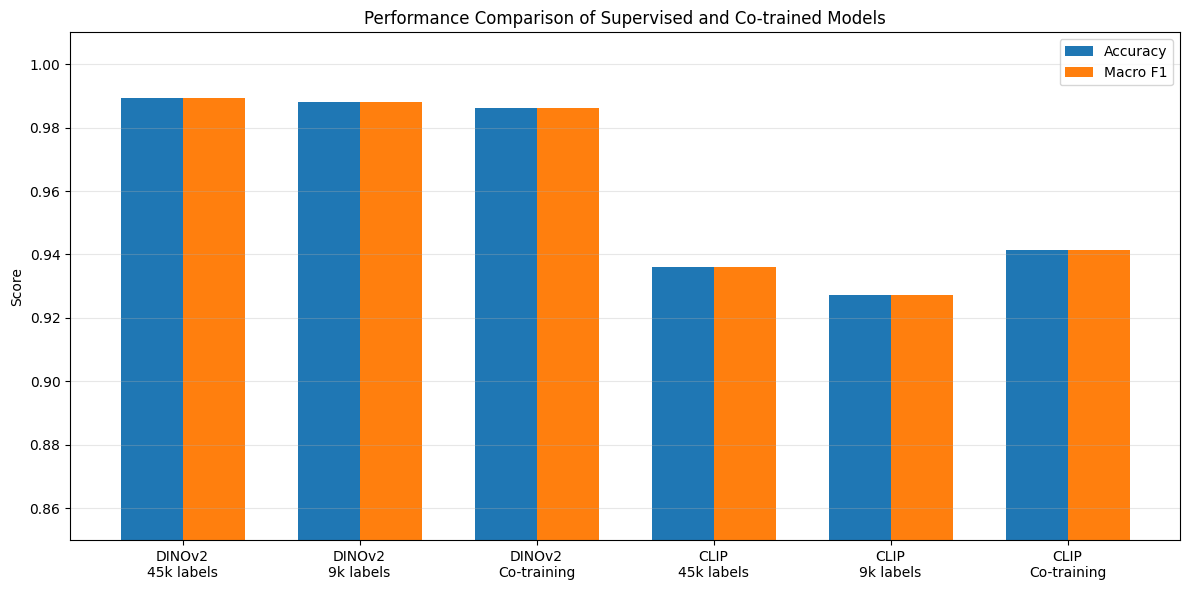

In [75]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "DINOv2\n45k labels",
    "DINOv2\n9k labels",
    "DINOv2\nCo-training",
    "CLIP\n45k labels",
    "CLIP\n9k labels",
    "CLIP\nCo-training"
]

accuracy = [
    0.9893,
    0.9881,
    0.9860,
    0.9360,
    0.9271,
    0.9413
]

macro_f1 = [
    0.9893,
    0.9881,
    0.9860,
    0.9360,
    0.9271,
    0.9413
]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x - width/2, accuracy, width, label="Accuracy")
ax.bar(x + width/2, macro_f1, width, label="Macro F1")

ax.set_ylabel("Score")
ax.set_title("Performance Comparison of Supervised and Co-trained Models")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0.85, 1.01)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()